# Comparison: `fastpiclef` vs the reference codes

A reproducible, single-machine comparison of the wave-optics Fresnel-integral solvers in `refs/`
against `fastpiclef`. This notebook **runs the harness live** and compiles all results.

**Method & fairness**
* Compared quantity: the raw integral $\int e^{i\omega\phi}\,dx$ (convention-free; the amplification
  $F$ is a fixed rescaling of it).
* **Truth**: our machine-precision *thimble* result, independently validated — it agrees with a
  method-independent brute-force referee (raw-integrand quadrature + exact Fresnel tails) to that
  referee's ~$10^{-6}$ floor, and with the exact Airy function to $3\times10^{-15}$. Grading an
  *independent* code (plind) against it is fair.
* **Single-threaded** (`RAYON_NUM_THREADS = OMP_NUM_THREADS = 1`); threaded speed is a separate axis.
* The apples-to-apples *algorithmic* row is `fastpiclef/mesh` vs `plind` (same PL-flow method); the
  `thimble` path (Shi's constant-phase-contour method, which plind lacks) is our additional edge.

*Run this notebook in the env that has both Jupyter and the reference codes:*
`pixi run -e notebook lab` — or headless via `pixi run execute-comparison`.

In [1]:
import os, sys
root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(root, 'pyproject.toml')) and root != '/':
    root = os.path.dirname(root)
sys.path.insert(0, root); os.chdir(root)

import comparison.run as H          # sets single-thread pin, then imports fastpiclef
import comparison.cases as C
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('repo root :', root)
print('threads   : RAYON =', os.environ.get('RAYON_NUM_THREADS'), ' OMP =', os.environ.get('OMP_NUM_THREADS'))
print('cases     :', [c.name for c in C.CASES])

repo root : /home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code
threads   : RAYON = 1  OMP = 1
cases     : ['rational b=0.3 k=-2.0 w=10', 'rational b=0.3 k=0.2 w=1', 'airy y=1.0 w=1']


## 1. Reference sanity — is our 'truth' trustworthy?

Our thimble truth vs the independent brute-force referee. They agree down to the referee's own
~$10^{-6}$ floor (its analytic tail neglects the potential's tail), which is why it is used only as a
cross-check, not to grade sub-$10^{-6}$ solvers. (For Airy the truth *is* the exact Airy function.)

In [2]:
san = pd.DataFrame(
    [(c.name, H.rel(c.truth, c.referee)) for c in C.CASES],
    columns=['case', 'thimble vs brute-force referee'])
san.style.format({'thimble vs brute-force referee': '{:.1e}'}).hide(axis='index')

case,thimble vs brute-force referee
rational b=0.3 k=-2.0 w=10,3.3e-05
rational b=0.3 k=0.2 w=1,2.2e-06
airy y=1.0 w=1,0.0e+00


## 2. Accuracy & speed (single-threaded)

Relative error (vs the validated truth) and median wall time over repetitions.

In [3]:
df = H.summary_table()            # runs fastpiclef (thimble+mesh) and plind on each case
df['time (ms)'] = df['time_s'] * 1e3
df[['case', 'solver', 'rel_err', 'time (ms)']].style.format(
    {'rel_err': '{:.2e}', 'time (ms)': '{:.2f}'}).hide(axis='index')

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961
total steps: 12 current time: 1.5658250587466271


total steps: 12 current time: 1.5658250587466271
total steps: 12 current time: 1.5658250587466271


... (2 outputs left out)

total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


case,solver,rel_err,time (ms)
rational b=0.3 k=-2.0 w=10,fastpiclef/auto,0.00e+00,0.49
rational b=0.3 k=-2.0 w=10,fastpiclef/mesh,7.22e-15,4.95
rational b=0.3 k=-2.0 w=10,plind,6.64e-03,2247.46
rational b=0.3 k=0.2 w=1,fastpiclef/auto,0.00e+00,0.28
rational b=0.3 k=0.2 w=1,fastpiclef/mesh,1.68e-13,9.46
rational b=0.3 k=0.2 w=1,plind,2.95e-10,123.16
airy y=1.0 w=1,fastpiclef/auto,2.90e-15,0.21
airy y=1.0 w=1,fastpiclef/mesh,6.60e-16,3.87
airy y=1.0 w=1,plind,2.12e-07,453.63


### Headline: fastpiclef (auto) vs plind

In [4]:
piv = df.pivot_table(index='case', columns='solver', values='time_s')
head = pd.DataFrame({
    'plind time (s)': piv['plind'],
    'fastpiclef time (ms)': piv['fastpiclef/auto'] * 1e3,
    'speedup': piv['plind'] / piv['fastpiclef/auto'],
})
head.style.format({'plind time (s)': '{:.3f}', 'fastpiclef time (ms)': '{:.2f}', 'speedup': '{:.0f}x'})

,plind time (s),fastpiclef time (ms),speedup
case,,,
airy y=1.0 w=1,0.454,0.21,2148x
rational b=0.3 k=-2.0 w=10,2.247,0.49,4603x
rational b=0.3 k=0.2 w=1,0.123,0.28,444x


## 3. The real differentiator: error vs cost

How accuracy scales with wall time (the resolution knob is swept for each flow method). `fastpiclef`
sits at the bottom-left (fast **and** machine-precise — the adaptive stopping means the mesh does not
trade accuracy for cost); `plind` at the top-right. The thimble ★ is the reference (fastest, exact).

total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.539269997668487


total steps: 32 current time: 1.539269997668487
total steps: 32 current time: 1.539269997668487


total steps: 32 current time: 1.539269997668487
total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286
total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286


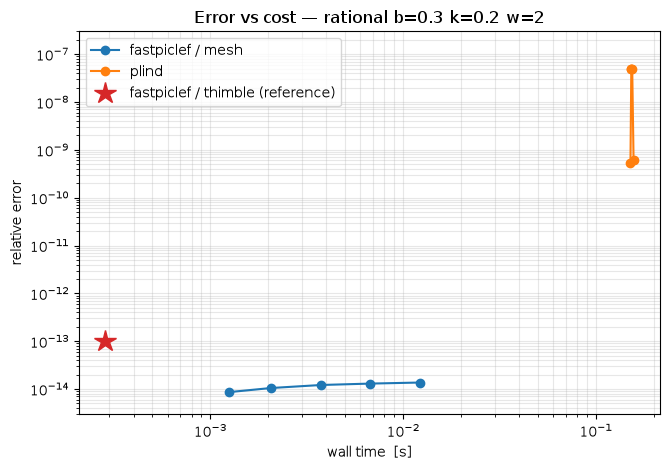

In [5]:
case, series, thimble_pt = H.convergence_curve()
fig, ax = plt.subplots(figsize=(6.8, 4.8))
H.plot_convergence(ax, case, series, thimble_pt)
plt.tight_layout(); plt.show()

## Interpretation & caveats

* Across all cases `fastpiclef` is **~300–5000× faster than `plind` and more accurate**, single-threaded.
* Part of the raw speedup is Rust-vs-Python; part is genuinely better algorithms. The `mesh`-vs-`plind`
  row isolates the former (~100× at the same PL-flow method), the `thimble` the latter.
* `plind` ran with reasonable-but-not-hand-tuned descent parameters; the convergence curve sweeps its
  resolution so the comparison is against its whole error-vs-cost frontier, not one point.
* Single-threaded only. Threaded performance (our rayon vs plind/P-LPI OpenMP vs FIONA multiprocessing)
  is a separate axis, added later.

## Still to come (this notebook will grow)

* **P-LPI** (C++): its built-in case is exactly `RationalLens(kappa=-2)` swept over source position at
  $\nu=10$ — a shared benchmark and a *three-way* PL cross-check (fastpiclef ≈ plind ≈ P-LPI).
* **FIONA** (FFT/NUFHT): on a shared lens (point mass ⇒ the Nakamura–Deguchi closed form as external
  truth), run in its native $(\omega, y)$-grid protocol where an FFT method is judged fairly.
* **2D** comparisons and a written summary.